# This Project for me Learning How to code Linear Regression in Machine Learning 

## Import Library what we need

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

## Load Dataset

In [4]:
df = pd.read_csv('../dataset/train_housePrices.csv')

## Data Understanding

In [8]:
df.shape

(1460, 81)

In [9]:
df.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [6]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Exploratory Data Analysis (EDA)

In [30]:
# Check Missing Value
print(df.isnull().sum().sort_values(ascending=False))


PoolQC           1453
MiscFeature      1406
Alley            1369
Fence            1179
MasVnrType        872
                 ... 
MoSold              0
YrSold              0
SaleType            0
SaleCondition       0
SalePrice           0
Length: 81, dtype: int64


In [32]:
# Check duplicate data
print(df.duplicated().sum())

0


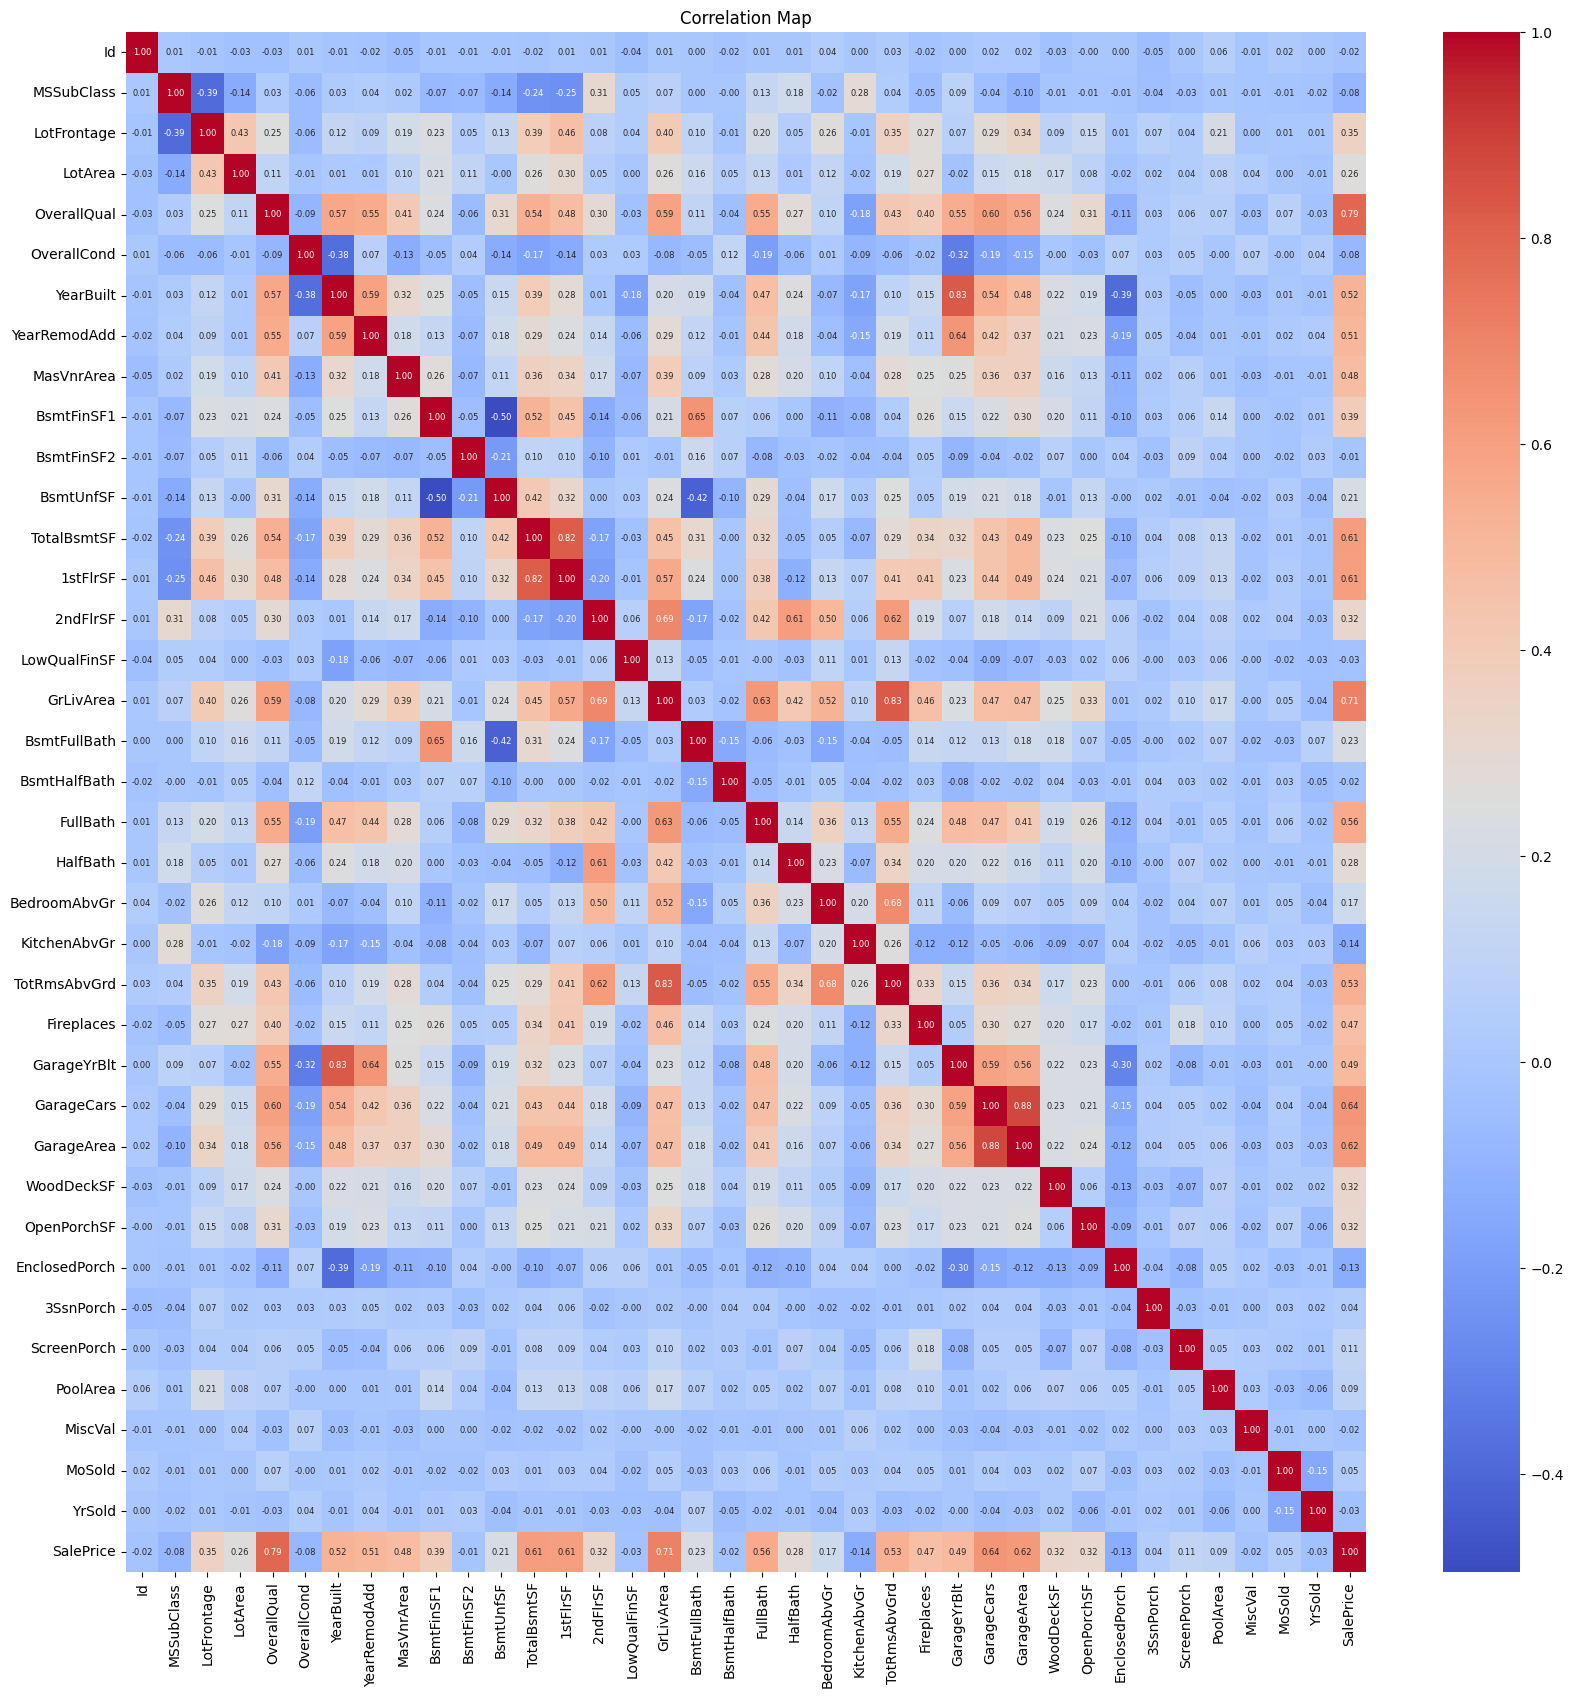

In [20]:
# Visulatization Correlation
corr = df.corr(numeric_only=True)
plt.figure(figsize=(20,20))
sns.heatmap(
    corr, 
    annot=True, 
    cmap="coolwarm",
    fmt=".2f",
    annot_kws={"size":6}
)
plt.title("Correlation Map")
plt.show()

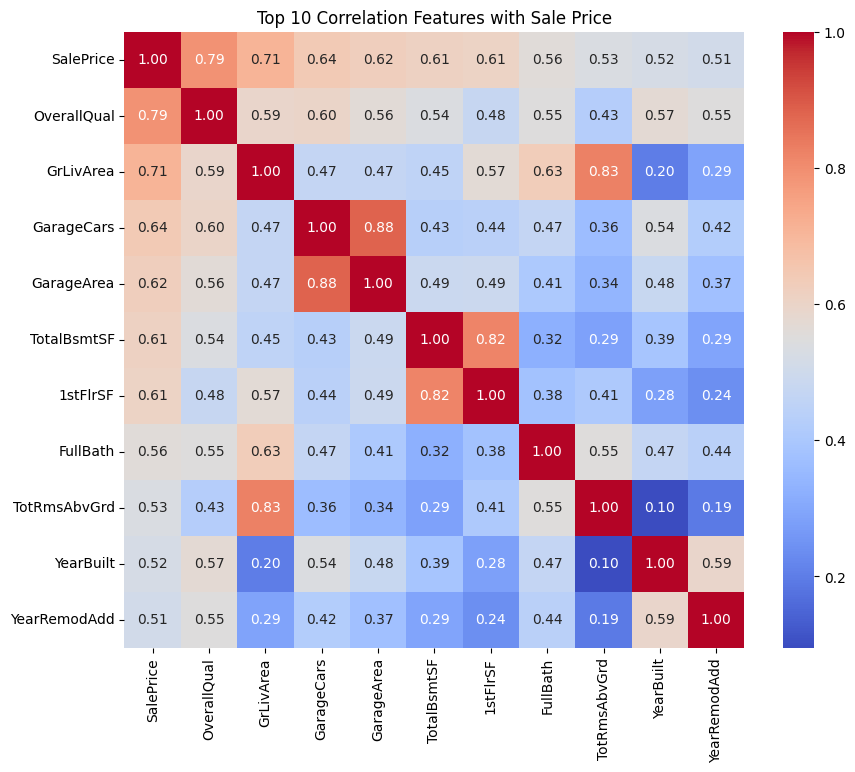

In [ ]:
# Correlation map for top 10 Features
corr = df.corr(numeric_only=True)

top_corr = (
    corr['SalePrice']
    .abs()
    .sort_values(ascending=False)
    .head(11)
)

top_features = top_corr.index

plt.figure(figsize=(10,8))
sns.heatmap(
    corr.loc[top_features, top_features],
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Top 10 Correlation Features with Sale Price")
plt.show()

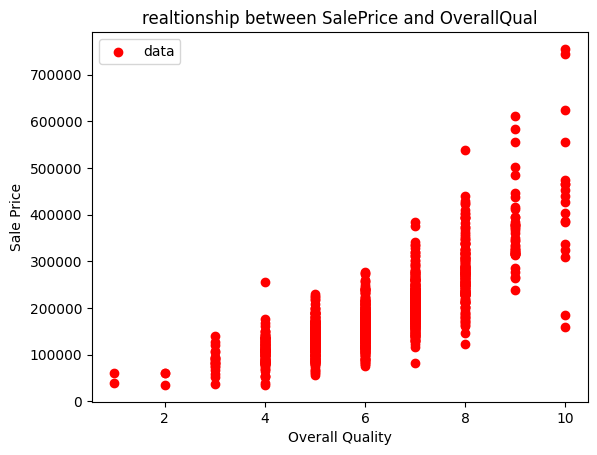

In [29]:
# Make Scatter Visualization
plt.scatter(x=df['OverallQual'], y=df['SalePrice'], color='red', label='data')
plt.xlabel('Overall Quality')
plt.ylabel("Sale Price")
plt.legend()
plt.title("realtionship between SalePrice and OverallQual")
plt.show()

# Conlucions
# We can see at visulization, relation between SP and AQ enough strong but we still can see outlier on 10 OQ and 700000 SP 

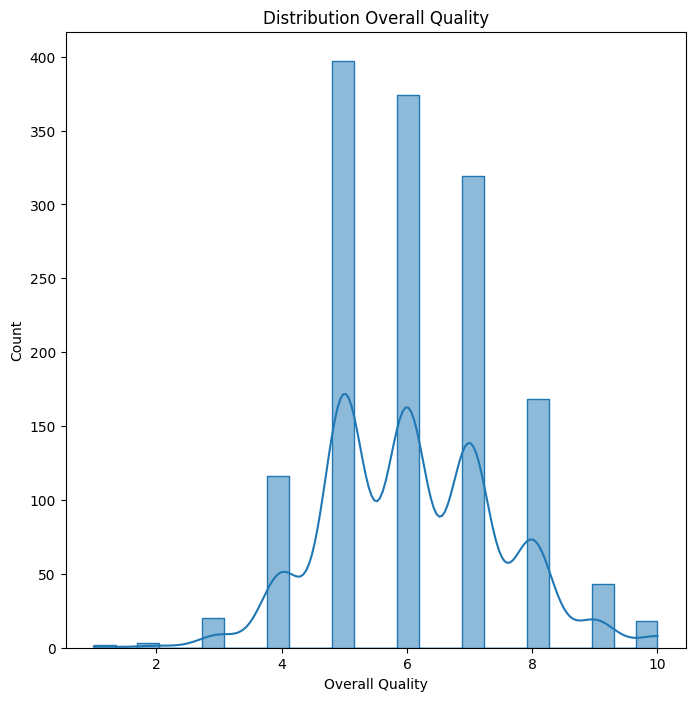

In [42]:
# Check Distribution X 
plt.figure(figsize=(8,8))
sns.histplot(data= df, x=df['OverallQual'], kde=True, element='step')
plt.xlabel("Overall Quality")
plt.ylabel("Count")
plt.title("Distribution Overall Quality")
plt.show()


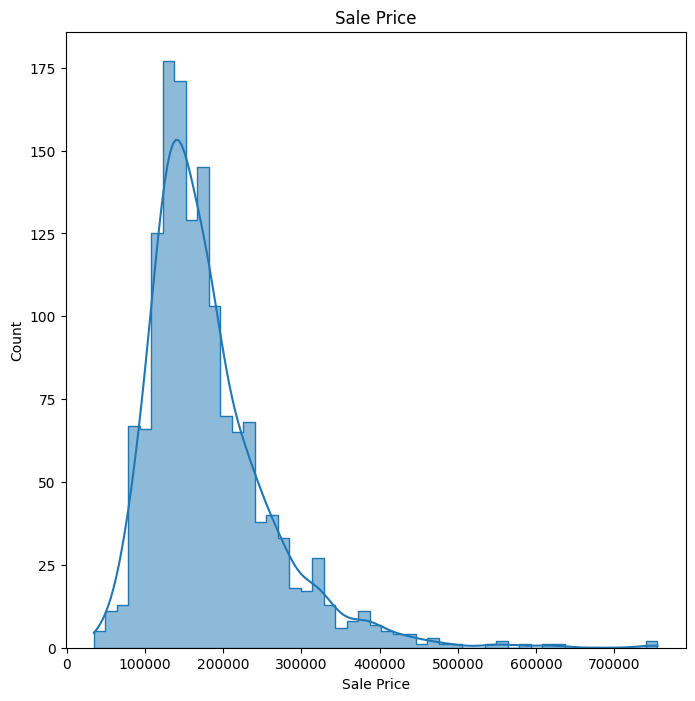

In [43]:
# Check Distribution y 
plt.figure(figsize=(8,8))
sns.histplot(data= df, x=df['SalePrice'], kde=True, element='step')
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.title("Sale Price")
plt.show()

C:\Users\ROG\AppData\Local\Temp\ipykernel_28144\3297588854.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


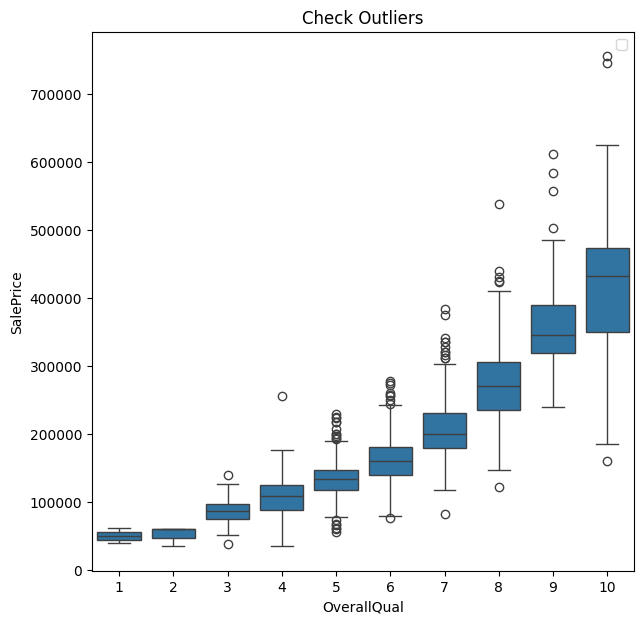

In [40]:
# We gonna check outliers between SP and OQ
plt.figure(figsize=(7,7))
sns.boxplot(data= df, x=df['OverallQual'],y=df['SalePrice'])
plt.title("Check Outliers")
plt.legend()
plt.show()

## Data Cleaning
### We gonna drop coloumn
- PoolQC           1453
- MiscFeature      1406
- Alley            1369
- Fence            1179
Because the missing value > 50%, so i decide to drop them, and we can see at corr map they're not in 10 features strongest

In [ ]:
# Drop Coloumn
df = df.drop('PoolQC', axis=1)
df = df.drop('MiscFeature', axis=1)
df = df.drop('Alley', axis=1)
df = df.drop('Fence', axis=1)

print("Drop Column Success")

In [38]:
# Check missing value after drop coloumn
print(df.isnull().sum().sort_values(ascending=False).to_string())

MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageFinish      81
GarageQual        81
GarageCond        81
GarageType        81
GarageYrBlt       81
BsmtExposure      38
BsmtFinType2      38
BsmtCond          37
BsmtFinType1      37
BsmtQual          37
MasVnrArea         8
Electrical         1
LandSlope          0
LotConfig          0
Condition1         0
Neighborhood       0
LotShape           0
Street             0
LotArea            0
MSZoning           0
MSSubClass         0
Id                 0
Utilities          0
LandContour        0
RoofStyle          0
YearRemodAdd       0
Foundation         0
ExterCond          0
ExterQual          0
Exterior2nd        0
RoofMatl           0
Exterior1st        0
BsmtFinSF2         0
BsmtFinSF1         0
BsmtUnfSF          0
TotalBsmtSF        0
Condition2         0
BldgType           0
OverallCond        0
YearBuilt          0
HouseStyle         0
OverallQual        0
LowQualFinSF       0
2ndFlrSF           0
1stFlrSF     

In [45]:
# i will fill MasVnrType with None, because this coloumn might be use later
df['MasVnrType'] = df['MasVnrType'].fillna('None')
print("Fill Succes")

# Check Missing Value :
print(df.isnull().sum().sort_values(ascending=False).to_string())

FireplaceQu      690
LotFrontage      259
GarageFinish      81
GarageYrBlt       81
GarageQual        81
GarageCond        81
GarageType        81
BsmtExposure      38
BsmtFinType2      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Neighborhood       0
LandSlope          0
LotConfig          0
Condition1         0
LandContour        0
LotShape           0
Street             0
LotArea            0
MSZoning           0
MSSubClass         0
Id                 0
Utilities          0
RoofMatl           0
RoofStyle          0
Condition2         0
Foundation         0
ExterCond          0
ExterQual          0
MasVnrType         0
Exterior1st        0
Exterior2nd        0
BsmtFinSF2         0
BsmtFinSF1         0
BsmtUnfSF          0
TotalBsmtSF        0
HouseStyle         0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
OverallQual        0
LowQualFinSF       0
2ndFlrSF           0
1stFlrSF     

## Data Handling
because we have other coloumn with missing value but < 50%, so i will fill those coloumn with any metode

In [46]:
# These coloumn will be fill with None because these coloumn is Categorical
cols_none =[
    "FireplaceQu",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "GarageType",
    "BsmtExposure",
    "BsmtCond",
    "BsmtQual",
    "BsmtFinType1",
    "BsmtFinType2"
]
df[cols_none] = df[cols_none].fillna('None')
print("Fill Success")

print(df.isnull().sum().sort_values(ascending=False).to_string())

Fill Success
LotFrontage      259
GarageYrBlt       81
MasVnrArea         8
Electrical         1
Id                 0
Street             0
LotShape           0
LandContour        0
Utilities          0
LotConfig          0
MSSubClass         0
MSZoning           0
LotArea            0
Condition1         0
Neighborhood       0
LandSlope          0
HouseStyle         0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Condition2         0
RoofStyle          0
RoofMatl           0
Exterior2nd        0
Exterior1st        0
MasVnrType         0
ExterQual          0
ExterCond          0
BldgType           0
Foundation         0
BsmtQual           0
BsmtExposure       0
BsmtCond           0
BsmtFinSF1         0
BsmtFinType2       0
BsmtFinSF2         0
BsmtFinType1       0
BsmtUnfSF          0
TotalBsmtSF        0
HeatingQC          0
Heating            0
CentralAir         0
1stFlrSF           0
2ndFlrSF           0
OverallQual        0
LowQualFinSF       0
GrLivArea          0


In [47]:
# coloumn LotFrontage will be fill with groupby Neighborhood and median
df['LotFrontage'] = (
    df.groupby('Neighborhood')['LotFrontage']
    .transform(lambda x: x.fillna(x.median())))
print("Median Fill Success\n")
print(df.isnull().sum().sort_values(ascending=False).to_string())

Median Fill Success

GarageYrBlt      81
MasVnrArea        8
Electrical        1
MSSubClass        0
Id                0
Street            0
LotShape          0
LandContour       0
Utilities         0
LotConfig         0
MSZoning          0
LotFrontage       0
LotArea           0
Condition1        0
Neighborhood      0
LandSlope         0
HouseStyle        0
OverallCond       0
YearBuilt         0
YearRemodAdd      0
Condition2        0
RoofStyle         0
RoofMatl          0
Exterior2nd       0
Exterior1st       0
MasVnrType        0
ExterQual         0
ExterCond         0
BldgType          0
Foundation        0
BsmtQual          0
BsmtExposure      0
BsmtCond          0
BsmtFinSF1        0
BsmtFinType2      0
BsmtFinSF2        0
BsmtFinType1      0
BsmtUnfSF         0
TotalBsmtSF       0
HeatingQC         0
Heating           0
CentralAir        0
1stFlrSF          0
2ndFlrSF          0
OverallQual       0
LowQualFinSF      0
GrLivArea         0
BsmtHalfBath      0
BsmtFullBath      0

In [48]:
# Coloumn GarageYrBlt will be fill with 0 because i assume if NaN in this coloumn its mean 0 garage
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)
print("Fill Success")

Fill Success


In [49]:
# Coloumn MasVnrArea will be fill with 0
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
print("Fill Success")

Fill Success


In [50]:
# Coloumn Electrical Mode
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])
print("Fill Success")

Fill Success


In [51]:
# Check Missing Value after we handling those data
print(df.isnull().sum().sort_values(ascending=False).to_string())

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
KitchenQual 

## Splitting Data first model

In [60]:
# Import Library
from sklearn.model_selection import train_test_split

# Feature Selection
X = df[['OverallQual']]
y = df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # this will be separate 80 : 20
    random_state= 42
)

print(f"Total X Train : {len(X_train)}")
print(f"Total X Test : {len(X_test)}")

Total X Train : 1168
Total X Test : 292


## second Model with multiple Linear Regression

In [ ]:
selected_feature = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'GarageArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'FullBath',
    'YearBuilt'
]
X_sec = df[selected_feature]
y_sec = df['SalePrice']

X_train_sec, X_test_sec, y_train_sec, y_test_sec = train_test_split(
    X_sec,
    y_sec,
    test_size= 0.2,
    random_state=42
)

print(f"Total X_train_sec : {len(X_train_sec)}")
print(f"Total X_test_sec : {len(X_test_sec)}")

Total X_train_sec : 1168
Total X_test_sec : 292


## Train Model

In [61]:
# Import Library
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Train Success")

Train Success


## Second Train Model

In [78]:
model_2 = LinearRegression()
model_2.fit(X_train_sec, y_train_sec)
print("Train Model 2 Success")

Train Model 2 Success


## Print Slope and Intercept

In [ ]:
print("Slope : ", model.coef_[0])
print("Intercept : ", model.intercept_)

# each 1 point increase in OverallQual is estimated to raise the house
# price by approximately $44.38, assuming other factors remain constant

Slope :  44379.87767098291
Intercept :  -90233.22290028064


## print Second Slope and Intercept

In [ ]:
print("Slope : ", model_2.coef_[0])
print("Intercept : ", model_2.intercept_)
#A one-unit increase in the selected feature is associated with an 
# estimated $10,463 increase in SalePrice, holding all other selected 
# features constant.

Slope :  10463.037645420147
Intercept :  -782834.0645831812


## Do prediction

In [64]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[176046.04312562 264805.79846758 131666.16545463 176046.04312562
 309185.67613857  87286.28778365 220425.9207966  176046.04312562
  87286.28778365 131666.16545463]


## Do second Prediction

In [80]:
y_pred_sec = model_2.predict(X_test_sec)
print(y_pred_sec[:10])

[143149.93245595 296621.69898625 118933.81530292 173345.76750245
 291325.44473488  55521.18475094 210027.68581572 170328.98308481
  54799.98787119 129501.93287743]


## Visualization Predict and Test

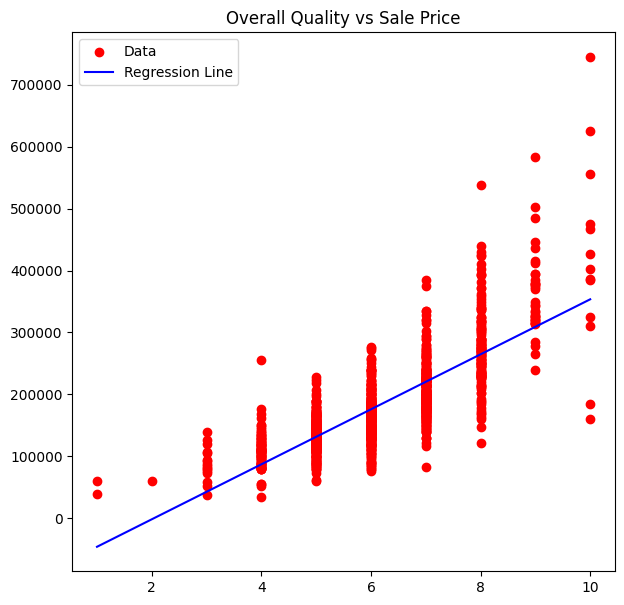

In [74]:
# Make Linear line
x_line = np.linspace(
    X_train['OverallQual'].min(),
    X_train['OverallQual'].max(),
    100
)
y_line = model.intercept_ + model.coef_[0] * x_line


plt.figure(figsize=(7,7))
plt.scatter(X_train,y_train, color='red', label='Data')
plt.plot(x_line, y_line, color='blue', label='Regression Line')
plt.title("Overall Quality vs Sale Price")
plt.legend()
plt.show()

## Evaluation MAE, RMSE, R2

In [76]:
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred)) 
r2 = r2_score(y_test, y_pred)

print(f"MAE Result (Average miss prediction) : {mae:.2%}")
print(f"RMAE Result (Error Sensitve) : {rmse:.2%}")
print(f"R2 Result (Result Explenation)) : {r2:.2%}")

MAE Result (Average miss prediction) : 3334324.21%
RMAE Result (Error Sensitve) : 5177862.65%
R2 Result (Result Explenation)) : 65.05%


## Evaluation Result:
The model yielded an MAE of 33,343.24, meaning the average *SalePrice* prediction differs from the actual value by approximately 33,343. 
An RMSE of 51,778.63 indicates the presence of some predictions with significant errors. The model achieved an R² value of 0.65, 
meaning that approximately 65% ​​of the variation in *SalePrice* can be explained by *OverallQual*. Although the model demonstrates a reasonably good relationship, 
about 35% of the price variation remains unexplained. This is likely because the model utilizes only 
a single feature, meaning other factors influencing house prices have not been taken into account..

## Second Evaluation MAE, RMSE, R2

In [ ]:
mae_sec = mean_absolute_error(y_test_sec, y_pred_sec)
rmse_sec = np.sqrt(mean_squared_error(y_test_sec, y_pred_sec))
r2_sec = r2_score(y_test_sec, y_pred_sec)

print("Sec MAE : ", mae_sec)
print("Sec RMSE : ", rmse_sec)
print("R Squared : ", r2_sec)

Sec MAE :  24932.66719234004
Sec RMSE :  39558.88050828559
R Squared :  0.7959793384533639


## Evaluation Result
The Multiple Linear Regression model outperformed the Simple Linear Regression model. The R² increased from 0.65 to 0.796, while both MAE and RMSE decreased. This indicates that incorporating multiple relevant features improved the model's ability to predict SalePrice.

## Residual
- checking whether errors are randomly distributed
- verifying the suitability of the linear model

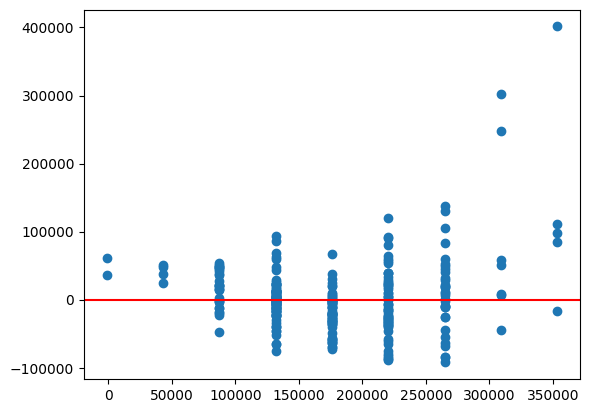

In [73]:
residual = y_test - y_pred
plt.scatter(y_pred, residual)
plt.axhline(0, color='red')

## Second Residual

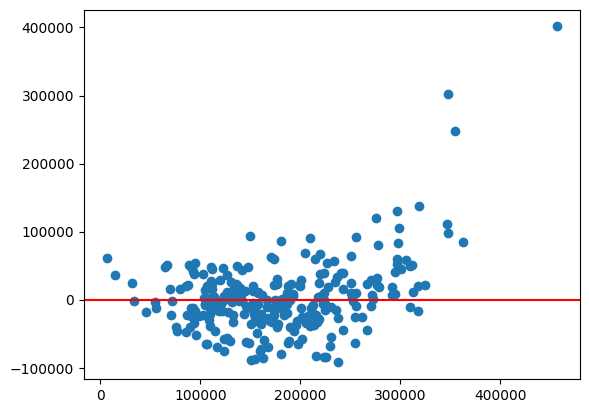

In [84]:
sec_residual = y_test_sec - y_pred_sec
plt.scatter(y_pred_sec, residual)
plt.axhline(0, color="red")

## Residual Result
Most residuals are distributed around zero, which indicates that the model's predictions are generally centered around the actual values. However, the residual plot shows an increasing spread at higher predicted values and several large residuals, suggesting possible heteroscedasticity and outliers.

## Final Visualization

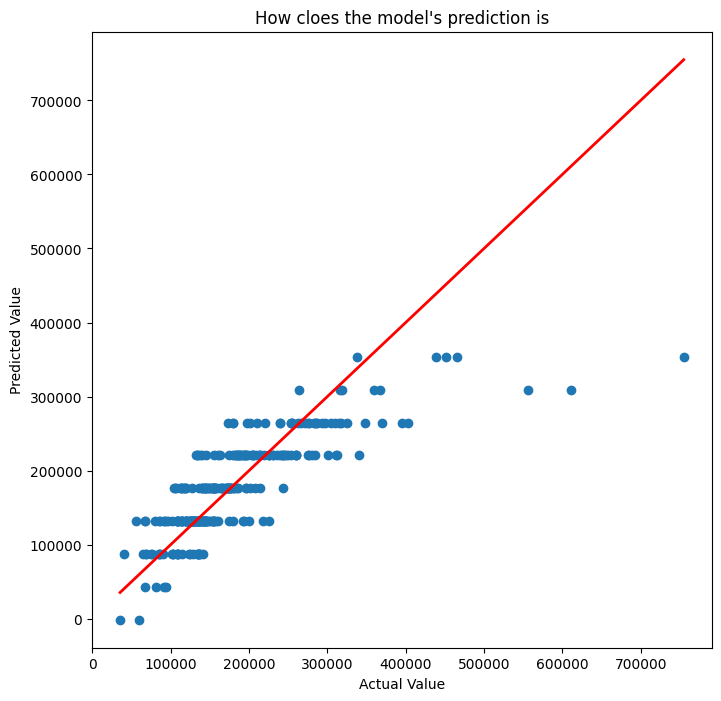

In [72]:
plt.figure(figsize=(8,8))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r-', lw=2)
plt.xlabel("Actual Value")
plt.ylabel("Predicted Value")
plt.title("How cloes the model's prediction is")
plt.show()

## Sec Final Visualization

C:\Users\ROG\AppData\Local\Temp\ipykernel_28144\39111574.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


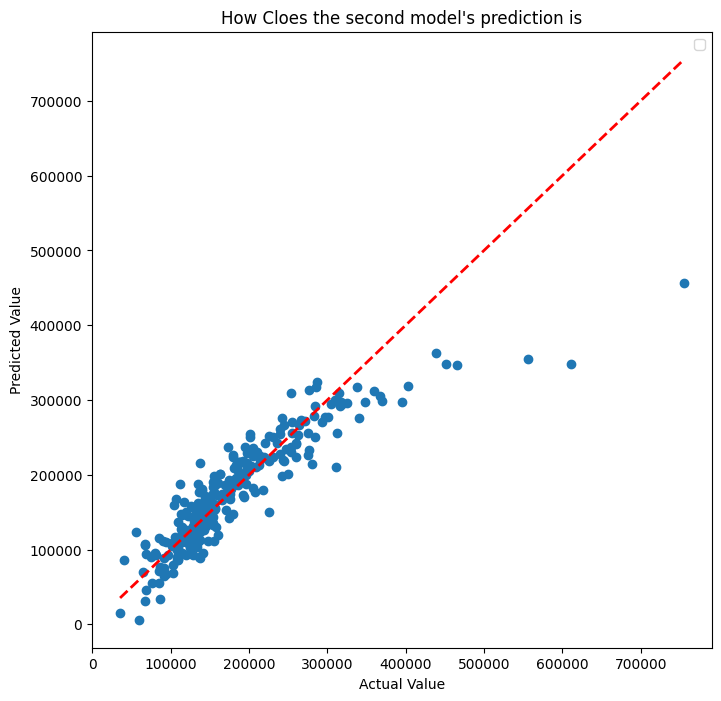

In [86]:
plt.figure(figsize=(8,8))
plt.scatter(y_test_sec, y_pred_sec)
plt.plot([y_test_sec.min(), y_test_sec.max()],[y_test_sec.min(), y_test_sec.max()], 'r--', lw=2)
plt.xlabel("Actual Value")
plt.ylabel("Predicted Value")
plt.title("How Cloes the second model's prediction is")
plt.legend()
plt.show()

## Interpretaion Second Visualization

The second model performs better than the baseline model, with an R² score of approximately 79.6%. However, the model still struggles to accurately predict houses with high SalePrice, as the prediction errors become larger for more expensive houses.